# Student 1 Individual Notebook

Natalie Schweickert

Student 1: A penalized (Ridge, Lasso or ElasticNet) linear model (Linear Regression or Logistic Regression, as appropriate) AND a Support Vector Machine.

## Model Training and Optimization

In [1]:
# import
import pandas as pd

# read training dataset
df = pd.read_csv("../../Data/training.csv")
df.head()

,rev_util,age,late_30_59,debt_ratio,monthly_inc,open_credit,late_90,real_estate,late_60_89,dependents,dlq_2yrs
0,0.793106,35.0,1.0,0.098301,3000.0,3.0,0.0,0.0,1.0,4.0,1
1,1.000000,43.0,4.0,0.857017,2272.0,5.0,0.0,2.0,0.0,2.0,1
2,0.772902,78.0,0.0,2.414651,2811.0,21.0,0.0,1.0,0.0,0.0,0
3,2.099010,43.0,0.0,0.033319,2400.0,1.0,0.0,0.0,0.0,0.0,0
4,0.266185,49.0,0.0,0.179646,40000.0,16.0,0.0,3.0,0.0,3.0,0


In [2]:
# prepare data
X = df.drop(columns=['dlq_2yrs'])
y = df['dlq_2yrs']
print(X.head())
print(y)

   rev_util   age  late_30_59  debt_ratio  monthly_inc  open_credit  late_90  \
0  0.793106  35.0         1.0    0.098301       3000.0          3.0      0.0   
1  1.000000  43.0         4.0    0.857017       2272.0          5.0      0.0   
2  0.772902  78.0         0.0    2.414651       2811.0         21.0      0.0   
3  2.099010  43.0         0.0    0.033319       2400.0          1.0      0.0   
4  0.266185  49.0         0.0    0.179646      40000.0         16.0      0.0   

   real_estate  late_60_89  dependents  
0          0.0         1.0         4.0  
1          2.0         0.0         2.0  
2          1.0         0.0         0.0  
3          0.0         0.0         0.0  
4          3.0         0.0         3.0  
0        1
1        1
2        0
3        0
4        0
        ..
13366    0
13367    1
13368    0
13369    1
13370    0
Name: dlq_2yrs, Length: 13371, dtype: int64


In [3]:
# 80/20 split with stratification
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=1234
)

### Model 1: Baseline Logistic Regression

In [4]:
# imports
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

#  baseline pipeline
baseline_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1234
)

cv_scores = cross_val_score(
    baseline_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

print("Baseline CV ROC-AUC:", round(cv_scores.mean(), 4))
print("CV Standard Deviation:", round(cv_scores.std(), 4))

# Fit baseline model on full training data
baseline_pipeline.fit(X_train, y_train)

Baseline CV ROC-AUC: 0.7841
CV Standard Deviation: 0.0126


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['rev_util','age','late_30_59',...,'real_estate','late_60_89','dependents']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or o

### Model 2: Penalzed Logistic Regression

In [5]:
# penalized pipeline 

# imports
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [6]:
# train test split 
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1234,
    stratify=y
)

In [7]:
# create the pipeline
logistic_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(solver='liblinear', max_iter=5000))
])

# hyperparameter combinations
logistic_param_grid = {
    'model__penalty': ['l1', 'l2'],
    'model__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced']
}

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# grid search
logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    refit=True,
    verbose=1
)

# train and optimize
logistic_grid.fit(X_train, y_train)

# print best results
print("Best Parameters:", logistic_grid.best_params_)
print("Best CV ROC-AUC:", logistic_grid.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.1

Best Parameters: {'model__C': 100, 'model__class_weight': 'balanced', 'model__penalty': 'l2'}
Best CV ROC-AUC: 0.7866942247888121


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 ins

### Model 3: Support Vector Machine

In [8]:
# imports
from sklearn.svm import SVC

# create pipeline
svm_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', SVC(kernel='rbf'))
])

# hyperparameter combinations
svm_param_grid = {
    'model__C': [0.1, 1, 10, 100],
    'model__gamma': ['scale', 0.001, 0.01, 0.1, 1],
    'model__class_weight': [None, 'balanced']
}

# grid search
svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    refit=True,
    verbose=1
)

# train and optimize
svm_grid.fit(X_train, y_train)

# best results
print("Best Parameters:", svm_grid.best_params_)
print("Best CV ROC-AUC:", svm_grid.best_score_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best Parameters: {'model__C': 100, 'model__class_weight': 'balanced', 'model__gamma': 0.01}
Best CV ROC-AUC: 0.8175677110700639


## Presentation of Results

In [9]:
cv_results = pd.DataFrame({
    'Model': [
        'Baseline Logistic Regression',
        'Penalized Logistic Regression',
        'Kernel SVM'
    ],
    'Mean CV ROC-AUC': [
        cv_scores.mean(),
        logistic_grid.best_score_,
        svm_grid.best_score_
    ],
    'CV Standard Deviation': [
        cv_scores.std(),
        logistic_grid.cv_results_['std_test_score'][logistic_grid.best_index_],
        svm_grid.cv_results_['std_test_score'][svm_grid.best_index_]
    ],
    'Best Hyperparameters': [
        'Default parameters',
        logistic_grid.best_params_,
        svm_grid.best_params_
    ]
})

cv_results.round(4)

,Model,Mean CV ROC-AUC,CV Standard Deviation,Best Hyperparameters
0,Baseline Logistic Regression,0.7841,0.0126,Default parameters
1,Penalized Logistic Regression,0.7867,0.0078,"{'model__C': 100, 'model__class_weight': 'bala..."
2,Kernel SVM,0.8176,0.0129,"{'model__C': 100, 'model__class_weight': 'bala..."


In [10]:
print("Baseline Logistic Regression: No hyperparameter tuning")

print("Penalized Logistic Regression combinations:",
      len(logistic_grid.cv_results_['params']))

print("Kernel SVM combinations:",
      len(svm_grid.cv_results_['params']))

Baseline Logistic Regression: No hyperparameter tuning
Penalized Logistic Regression combinations: 24
Kernel SVM combinations: 40


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = []

models = {
    'Baseline Logistic Regression': baseline_pipeline,
    'Penalized Logistic Regression': logistic_grid.best_estimator_,
    'Kernel SVM': svm_grid.best_estimator_
}

results = []

for name, model_item in models.items():

    y_pred = model_item.predict(X_test)
    y_scores = model_item.decision_function(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_scores),
        'PR-AUC': average_precision_score(y_test, y_scores)
    })

performance_df = pd.DataFrame(results)

performance_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Baseline Logistic Regression,0.7226,0.7685,0.6375,0.6969,0.7949,0.8117
1,Penalized Logistic Regression,0.7264,0.7760,0.6368,0.6995,0.7955,0.8123
2,Kernel SVM,0.7391,0.8333,0.5979,0.6963,0.8222,0.8363


In [12]:
from sklearn.model_selection import cross_validate

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

for name, model_item in models.items():

    cv_metrics = cross_validate(
        model_item,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    print(f"\n{name}")

    for metric in scoring:
        print(
            metric,
            round(cv_metrics[f'test_{metric}'].mean(), 4),
            "+/-",
            round(cv_metrics[f'test_{metric}'].std(), 4)
        )


Baseline Logistic Regression
accuracy 0.7137 +/- 0.0112
precision 0.7607 +/- 0.0168
recall 0.624 +/- 0.0125
f1 0.6855 +/- 0.0118
roc_auc 0.7856 +/- 0.0076
pr_auc 0.8026 +/- 0.0058


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.1


Penalized Logistic Regression
accuracy 0.7154 +/- 0.0106
precision 0.7667 +/- 0.0151
recall 0.6195 +/- 0.0137
f1 0.6852 +/- 0.0119
roc_auc 0.7867 +/- 0.0078
pr_auc 0.8037 +/- 0.0058

Kernel SVM
accuracy 0.7426 +/- 0.0043
precision 0.8395 +/- 0.007
recall 0.6 +/- 0.0136
f1 0.6997 +/- 0.008
roc_auc 0.8176 +/- 0.0129
pr_auc 0.8318 +/- 0.0098


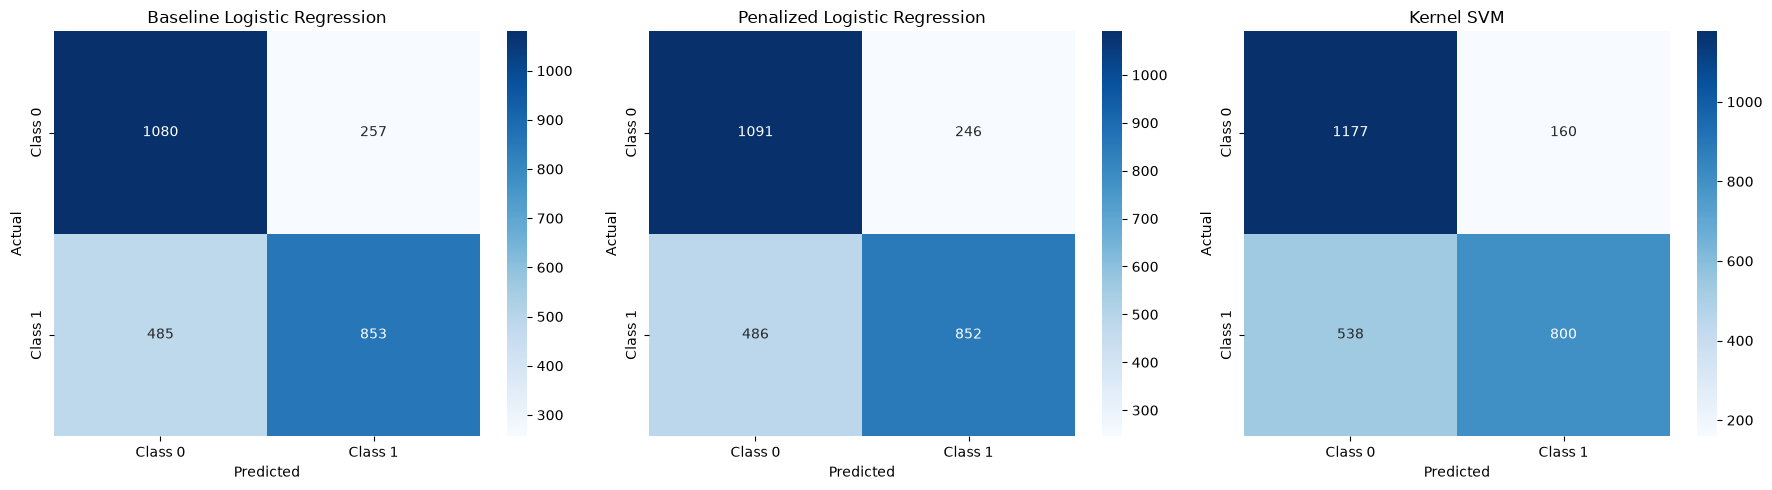

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model_item) in zip(axes, models.items()):

    y_pred = model_item.predict(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=['Class 0', 'Class 1'],
        yticklabels=['Class 0', 'Class 1']
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()